# Statistical validation

Read data

In [ ]:
topic_prevalence = pd.read_csv('topic_prevalence.csv')

In [3]:
G = nx.read_gexf('graph.gexf')
# Evaluate node attributes as literal
for node, data in G.nodes(data=True):
    if isinstance(data.get('topic_distribution'), str):
        data['topic_distribution'] = ast.literal_eval(
            data['topic_distribution']
        )

In [4]:
df_filtered = pd.read_csv('df_filtered.csv')

## Validation of assortativity coefficients: permutation tests

Null Model via Label Shuffling (Permutation Test)

In [5]:
# Parameters
n_permutations = 1000
topics = topic_prevalence.columns.drop('username')
topic_assortativity = {}
topic_pvalues = {}
topic_zscores = {}
random.seed(42)

for topic in topics:
    # Extract the attribute map for this topic
    topic_attribute_map = {
        node: data['topic_distribution'].get(topic, 0.0)
        for node, data in G.nodes(data=True)
        if data.get('topic_distribution') is not None
    }

    if not any(v > 0 for v in topic_attribute_map.values()):
        print(f"No nodes with prevalence > 0 for topic '{topic}'. Skipping.")
        topic_assortativity[topic] = None
        topic_pvalues[topic] = None
        continue

    # Assign the numeric attribute
    nx.set_node_attributes(G, topic_attribute_map, topic)

    # Compute observed assortativity
    try:
        r_obs = nx.numeric_assortativity_coefficient(G, topic)
    except Exception as e:
        print(f"Could not compute assortativity for topic '{topic}': {e}")
        r_obs = np.nan

    # Set to None if invalid
    if np.isnan(r_obs):
        topic_assortativity[topic] = None
        topic_pvalues[topic] = None
        continue

    # --- Permutation test ---
    nodes = sorted(topic_attribute_map.keys()) # sorted to ensure reproducibility
    values = [topic_attribute_map[node] for node in nodes]
    r_perm = np.zeros(n_permutations)

    for i in range(n_permutations):
        shuffled = dict(zip(nodes, random.sample(values, len(values))))
        nx.set_node_attributes(G, shuffled, topic)
        r_perm[i] = nx.numeric_assortativity_coefficient(G, topic)

    # Restore original distribution
    nx.set_node_attributes(G, topic_attribute_map, topic)

    # Compute statistics
    mean_null = np.mean(r_perm)
    std_null = np.std(r_perm)
    z_score = (r_obs - mean_null) / std_null if std_null > 0 else np.nan
    p_value = (np.sum(np.abs(r_perm - mean_null) >= np.abs(r_obs - mean_null)) + 1) / (n_permutations + 1)

    topic_assortativity[topic] = r_obs
    topic_pvalues[topic] = p_value
    topic_zscores[topic] = z_score

    print(f"\nTopic: {topic}")
    print(f"Observed assortativity: {r_obs:.4f}")
    print(f"Null mean: {mean_null:.4f} ± {std_null:.4f}")
    print(f"z-score: {z_score:.3f}, p-value: {p_value:.3f}")

# --- Summary ---
print("\n===== Permutation Test Results =====")
for topic in topics:
    if topic_assortativity.get(topic) is not None:
        print(f"{topic:45s}  r = {topic_assortativity[topic]:.4f} | z = {topic_zscores[topic]:.2f} | p = {topic_pvalues[topic]:.3f}")
    else:
        print(f"{topic:45s}  N/A")



Topic: Anti-establishment, lies and disinformation
Observed assortativity: 0.3972
Null mean: 0.0840 ± 0.0907
z-score: 3.454, p-value: 0.002

Topic: Anti-left
Observed assortativity: 0.5760
Null mean: 0.0864 ± 0.0900
z-score: 5.441, p-value: 0.001

Topic: Antisemitism and islamophobia
Observed assortativity: 0.5314
Null mean: 0.0824 ± 0.0820
z-score: 5.477, p-value: 0.001

Topic: Immigration
Observed assortativity: 0.2909
Null mean: 0.0993 ± 0.1231
z-score: 1.557, p-value: 0.100

Topic: Nationalism and white supremacy
Observed assortativity: 0.7053
Null mean: 0.0887 ± 0.0931
z-score: 6.624, p-value: 0.001

Topic: Offline activism, mobilization and violence
Observed assortativity: 0.4802
Null mean: 0.0922 ± 0.1104
z-score: 3.513, p-value: 0.001

Topic: Online coordination
Observed assortativity: 0.5212
Null mean: 0.0952 ± 0.1368
z-score: 3.115, p-value: 0.007

Topic: Proud Boys/Antifa and the manosphere
Observed assortativity: 0.6180
Null mean: 0.0841 ± 0.0936
z-score: 5.707, p-value: 0

In [6]:
assort_df = pd.DataFrame({
    "topic": topics,
    "assortativity": [topic_assortativity.get(t) for t in topics],
    "z_score": [topic_zscores.get(t) for t in topics],
    "p_value": [topic_pvalues.get(t) for t in topics]
})

assort_df.sort_values("p_value", inplace=True)
# assort_df.to_csv('null_model_assort.csv')
assort_df

,topic,assortativity,z_score,p_value
1,Anti-left,0.576013,5.441339,0.000999
2,Antisemitism and islamophobia,0.531393,5.477122,0.000999
4,Nationalism and white supremacy,0.705340,6.624265,0.000999
5,"Offline activism, mobilization and violence",0.480155,3.513423,0.000999
7,Proud Boys/Antifa and the manosphere,0.618042,5.706582,0.000999
9,US politics and Trumpism,0.495300,4.089215,0.000999
0,"Anti-establishment, lies and disinformation",0.397206,3.453895,0.001998
8,UK politics and Brexit,0.504489,4.027491,0.001998
6,Online coordination,0.521171,3.115172,0.006993
3,Immigration,0.290865,1.556599,0.099900


## Temporal analysis

### Display topic assortativity over time

In [7]:
# Keep only forwarded messages
df_fwd = df_filtered[df_filtered['fwd_from'].notna()]
print(f'Number of forwarded messages: {len(df_fwd)}')

# Extract the source channel id
df_fwd['source_channel_id'] = df_fwd['fwd_from'].apply(ast.literal_eval).apply(lambda x: x.get('channel_id') if isinstance(x, dict) else None)

# Read Pushshift channel files to recover channel usernames from id
data = pd.read_json('channels.ndjson', lines=True)

# Format the json channel file in a pandas DataFrame
list_full_chats = data['full_chat'].to_list()
full_chats = pd.DataFrame(list_full_chats)
list_chats = [x for xs in data['chats'].to_list() for x in xs]
chats = pd.DataFrame(list_chats)
channels = chats.merge(full_chats, on='id', how='outer')

# Create the id to channel dict
id2username = channels.set_index('id')['username'].to_dict()
print(f'Total umber of (id, username) pairs in the Pushshit dataset: {len(id2username)}')

# Map channel id to username in df_fwd
df_fwd['source_channel_username'] = df_fwd['source_channel_id'].map(id2username)
df_fwd[['fwd_from','source_channel_id','source_channel_username']].sample(5)

Number of forwarded messages: 21273


C:\Users\167266\AppData\Local\Temp\ipykernel_13396\3783801727.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fwd['source_channel_id'] = df_fwd['fwd_from'].apply(ast.literal_eval).apply(lambda x: x.get('channel_id') if isinstance(x, dict) else None)


Total umber of (id, username) pairs in the Pushshit dataset: 29661


C:\Users\167266\AppData\Local\Temp\ipykernel_13396\3783801727.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fwd['source_channel_username'] = df_fwd['source_channel_id'].map(id2username)


,fwd_from,source_channel_id,source_channel_username
41034,"{'_': 'MessageFwdHeader', 'channel_id': 145951...",1.459513e+09,loomeredofficial
68,"{'_': 'MessageFwdHeader', 'channel_id': 144743...",1.447436e+09,RTandReport
30926,"{'_': 'MessageFwdHeader', 'channel_id': 147916...",1.479163e+09,TommyRobinsonNews
36660,"{'_': 'MessageFwdHeader', 'channel_id': 144087...",1.440870e+09,BritainFirst
765,"{'_': 'MessageFwdHeader', 'channel_id': 147916...",1.479163e+09,TommyRobinsonNews


In [8]:
# Ensure 'date' is datetime and set as index if not already
if not isinstance(df_fwd.index, pd.DatetimeIndex):
    df_fwd['date'] = pd.to_datetime(df_fwd['date'], errors='coerce')
    df_fwd = df_fwd.set_index('date')

# Create a dictionary to store yearly dataframes
yearly_df_fwd = {}

# Group by year and store in the dictionary
for year, group in df_fwd.groupby(df_fwd.index.year):
    yearly_df_fwd[year] = group.copy()

# Display the keys of the dictionary to show the years available
print("DataFrames available for the following years:")
print(list(yearly_df_fwd.keys()))

# Example: Display the first few rows of the dataframe for the first year
if yearly_df_fwd:
    first_year = list(yearly_df_fwd.keys())[0]
    print(f"\nFirst 5 rows of the dataframe for year {first_year}:")
    display(yearly_df_fwd[first_year].head())
else:
    print("\nNo data available to split by year.")

DataFrames available for the following years:
[2016, 2017, 2018, 2019]

First 5 rows of the dataframe for year 2016:


C:\Users\167266\AppData\Local\Temp\ipykernel_13396\1899173590.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fwd['date'] = pd.to_datetime(df_fwd['date'], errors='coerce')


,from_id,fwd_from,message,username,title,about,mistral_agent_predictions,clean_labels,source_channel_id,source_channel_username
date,,,,,,,,,,
2016-12-31 05:13:37+00:00,NaN,"{'_': 'MessageFwdHeader', 'channel_id': None, ...",What the fuck did you just fucking say about m...,WhiteIsRight,Alt-Right Shitlords Inc.,for all your pure-blooded American shitposting...,"['US politics and Trumpism', 'Anti-left']",US politics and Trumpism,NaN,NaN
2016-12-31 05:13:37+00:00,NaN,"{'_': 'MessageFwdHeader', 'channel_id': None, ...",What the fuck did you just fucking say about m...,WhiteIsRight,Alt-Right Shitlords Inc.,for all your pure-blooded American shitposting...,"['US politics and Trumpism', 'Anti-left']",Anti-left,NaN,NaN
2016-12-29 07:30:12+00:00,NaN,"{'_': 'MessageFwdHeader', 'channel_id': 108036...",How should #Israel respond ?\n\n#Netanyahu cri...,WhiteIsRight,Alt-Right Shitlords Inc.,for all your pure-blooded American shitposting...,"['UK politics and Brexit', 'US politics and Tr...",UK politics and Brexit,1.080362e+09,ClintonFoundation
2016-12-29 07:30:12+00:00,NaN,"{'_': 'MessageFwdHeader', 'channel_id': 108036...",How should #Israel respond ?\n\n#Netanyahu cri...,WhiteIsRight,Alt-Right Shitlords Inc.,for all your pure-blooded American shitposting...,"['UK politics and Brexit', 'US politics and Tr...",US politics and Trumpism,1.080362e+09,ClintonFoundation
2016-12-25 08:12:22+00:00,NaN,"{'_': 'MessageFwdHeader', 'channel_id': None, ...",Please use /pol/ wisely folks.,WhiteIsRight,Alt-Right Shitlords Inc.,for all your pure-blooded American shitposting...,['Online coordination'],Online coordination,NaN,NaN


In [9]:
# Dictionary to store topic prevalence for each year
yearly_topic_prevalence = {}

# Iterate through yearly dataframes
for year, df_year in yearly_df_fwd.items():
    print(f"Calculating topic prevalence for year: {year}")

    # Ensure there is data for the year
    if df_year.empty:
        print(f"No data for year {year}. Skipping topic prevalence calculation.")
        yearly_topic_prevalence[year] = None # Store None or an empty DataFrame
        continue

    # Calculate topic prevalence for the current year's data
    # Need to use the original df to get all topics, then filter for channels in df_year
    channels_in_year = pd.unique(df_year['username'].dropna()) # Get unique channels with non-NaN usernames in this year

    if len(channels_in_year) == 0:
         print(f"No channels with valid usernames in year {year}. Skipping topic prevalence calculation.")
         yearly_topic_prevalence[year] = None
         continue

    df_year_topics = df_filtered[df_filtered['username'].isin(channels_in_year)].copy()


    if df_year_topics.empty:
        print(f"No topic data found for channels active in year {year} in the original df. Skipping.")
        yearly_topic_prevalence[year] = None
        continue


    username_topic_counts_year = df_year_topics.groupby(['username', 'clean_labels']).size().unstack(fill_value=0)

    # Normalize to get prevalence
    # Handle cases where a channel might have 0 total topics after filtering
    row_sums = username_topic_counts_year.sum(axis=1)
    username_topic_counts_year = username_topic_counts_year.div(row_sums[row_sums != 0], axis=0)
    username_topic_counts_year = username_topic_counts_year.fillna(0) # Fill NaN with 0 for channels with no topics


    yearly_topic_prevalence[year] = username_topic_counts_year

# Display topic prevalence for each year (optional)
for year, topic_prev in yearly_topic_prevalence.items():
    print(f"\nTopic Prevalence for Year {year}:")
    display(topic_prev if topic_prev is not None else "No data")

Calculating topic prevalence for year: 2016
Calculating topic prevalence for year: 2017
Calculating topic prevalence for year: 2018
Calculating topic prevalence for year: 2019

Topic Prevalence for Year 2016:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
WhiteIsRight,0.175165,0.064617,0.123394,0.04165,0.13079,0.035812,0.182951,0.093032,0.022188,0.130401
pishroofficial,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000



Topic Prevalence for Year 2017:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
PoliticalMemes,0.128333,0.153333,0.033333,0.036667,0.071667,0.031667,0.148333,0.083333,0.085000,0.228333
WhiteIsRight,0.175165,0.064617,0.123394,0.041650,0.130790,0.035812,0.182951,0.093032,0.022188,0.130401
shapeshifters,0.077844,0.053892,0.329341,0.023952,0.233533,0.000000,0.095808,0.023952,0.137725,0.023952
whiteresistance,0.132075,0.031447,0.176101,0.069182,0.371069,0.018868,0.094340,0.081761,0.006289,0.018868



Topic Prevalence for Year 2018:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
PoliticalMemes,0.128333,0.153333,0.033333,0.036667,0.071667,0.031667,0.148333,0.083333,0.085000,0.228333
RAYA1012,0.000000,0.000000,0.000000,0.055556,0.055556,0.000000,0.222222,0.666667,0.000000,0.000000
SouthAfricaReports,0.156250,0.034722,0.020833,0.048611,0.204861,0.357639,0.125000,0.000000,0.027778,0.024306
WhiteIsRight,0.175165,0.064617,0.123394,0.041650,0.130790,0.035812,0.182951,0.093032,0.022188,0.130401
pishroofficial,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
puresodiumpolitics,0.176692,0.048872,0.233083,0.048872,0.334586,0.015038,0.052632,0.041353,0.030075,0.018797
shapeshifters,0.077844,0.053892,0.329341,0.023952,0.233533,0.000000,0.095808,0.023952,0.137725,0.023952
shrimpniggas2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.166667,0.000000,0.333333
theblackfront,0.076923,0.076923,0.076923,0.000000,0.307692,0.230769,0.230769,0.000000,0.000000,0.000000



Topic Prevalence for Year 2019:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
AltKnight,0.154348,0.071739,0.067391,0.056522,0.128261,0.082609,0.173913,0.176087,0.021739,0.067391
BlackonWhiteCrime,0.273810,0.011905,0.071429,0.119048,0.261905,0.154762,0.047619,0.035714,0.011905,0.011905
BloodAndSoil,0.000000,0.000000,0.000000,0.000000,0.818182,0.000000,0.181818,0.000000,0.000000,0.000000
Brexiteers,0.151575,0.059226,0.045545,0.043384,0.019982,0.079928,0.223762,0.068047,0.271287,0.037264
ChurchofRacism,0.083333,0.000000,0.270833,0.000000,0.500000,0.000000,0.125000,0.020833,0.000000,0.000000
EducatingLiberals,0.132743,0.238938,0.035398,0.044248,0.044248,0.008850,0.088496,0.053097,0.000000,0.353982
EsotericNationalSocialism,0.061033,0.021127,0.103286,0.002347,0.673709,0.011737,0.122066,0.004695,0.000000,0.000000
FaithInRace,0.082645,0.008264,0.289256,0.016529,0.400826,0.033058,0.136364,0.024793,0.000000,0.008264
FascistLibrary,0.063187,0.019918,0.199863,0.012363,0.282967,0.008242,0.399038,0.004808,0.002060,0.007555


In [10]:
# Dictionary to store graphs for each year
yearly_graphs = {}

# Iterate through yearly dataframes
for year, df_year in yearly_df_fwd.items():
    print(f"Creating graph for year: {year}")

    # Ensure there is data for the year
    if df_year.empty:
        print(f"No data for year {year}. Skipping graph creation.")
        yearly_graphs[year] = None # Store None
        continue

    # Build edge list for the current year, ensuring no NaNs in usernames
    edgelist_year = df_year.dropna(subset=['source_channel_username', 'username'])

    # Filter edgelist to include only channels present in both source and target lists within this year
    # This ensures we only build connections between channels active in this year AND present in the target list
    channels_in_year_username = edgelist_year['username'].unique()
    edgelist_year_filtered = edgelist_year[edgelist_year['source_channel_username'].isin(channels_in_year_username)]

    # Ensure there are edges in the year after filtering
    if edgelist_year_filtered.empty:
        print(f"No valid edges in year {year} after filtering. Skipping graph creation.")
        yearly_graphs[year] = None
        continue


    # Count the occurrences of each source-target pair to use as weights for the year graph
    weighted_edgelist_year = edgelist_year_filtered.groupby(['source_channel_username', 'username']).size().reset_index(name='weight')

    # Create a directed graph for the current year
    G_year = nx.from_pandas_edgelist(weighted_edgelist_year, source='source_channel_username', target='username', edge_attr='weight', create_using=nx.DiGraph())

    yearly_graphs[year] = G_year

# Print the number of nodes and edges for each yearly graph (optional)
for year, graph in yearly_graphs.items():
    if graph is not None:
        print(f"\nGraph for Year {year}: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges")
    else:
        print(f"\nGraph for Year {year}: Not created due to insufficient data.")

Creating graph for year: 2016
No valid edges in year 2016 after filtering. Skipping graph creation.
Creating graph for year: 2017
No valid edges in year 2017 after filtering. Skipping graph creation.
Creating graph for year: 2018
Creating graph for year: 2019

Graph for Year 2016: Not created due to insufficient data.

Graph for Year 2017: Not created due to insufficient data.

Graph for Year 2018: 5 nodes, 4 edges

Graph for Year 2019: 42 nodes, 140 edges


Focus on 2019 because only year that has more than 5 nodes

In [11]:
G_2019 = yearly_graphs[2019]

In [12]:
# Filter df_fwd for the year 2019
df_fwd_2019 = df_fwd.loc['2019'].copy()

# Create a dictionary to store monthly dataframes for 2019
monthly_df_fwd_2019 = {}

# Group by month and store in the dictionary
for month, group in df_fwd_2019.groupby(df_fwd_2019.index.month):
    monthly_df_fwd_2019[month] = group.copy()

# Dictionary to store graphs for each month in 2019
monthly_graphs_2019 = {}

# Iterate through monthly dataframes
for month, df_month in monthly_df_fwd_2019.items():
    print(f"Creating graph for month {month} in 2019")

    # Ensure there is data for the month
    if df_month.empty:
        print(f"No data for month {month} in 2019. Skipping graph creation.")
        monthly_graphs_2019[month] = None # Store None
        continue

    # Build edge list for the current month, ensuring no NaNs in usernames
    edgelist_month = df_month.dropna(subset=['source_channel_username', 'username'])

    # Filter edgelist to include only channels present in both source and target lists within this month
    # This ensures we only build connections between channels active in this month AND present in the target list
    channels_in_month_username = edgelist_month['username'].unique()
    edgelist_month_filtered = edgelist_month[edgelist_month['source_channel_username'].isin(channels_in_month_username)]


    # Ensure there are edges in the month after filtering
    if edgelist_month_filtered.empty:
        print(f"No valid edges in month {month} in 2019 after filtering. Skipping graph creation.")
        monthly_graphs_2019[month] = None
        continue

    # Count the occurrences of each source-target pair to use as weights for the month graph
    weighted_edgelist_month = edgelist_month_filtered.groupby(['source_channel_username', 'username']).size().reset_index(name='weight')

    # Create a directed graph for the current month
    G_month = nx.from_pandas_edgelist(weighted_edgelist_month, source='source_channel_username', target='username', edge_attr='weight', create_using=nx.DiGraph())

    monthly_graphs_2019[month] = G_month

# Print the number of nodes and edges for each monthly graph (optional)
for month, graph in monthly_graphs_2019.items():
    if graph is not None:
        print(f"\nGraph for 2019 Month {month}: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges")
    else:
        print(f"\nGraph for 2019 Month {month}: Not created due to insufficient data.")

Creating graph for month 1 in 2019


No valid edges in month 1 in 2019 after filtering. Skipping graph creation.
Creating graph for month 2 in 2019
Creating graph for month 3 in 2019
Creating graph for month 4 in 2019
Creating graph for month 5 in 2019
Creating graph for month 6 in 2019
Creating graph for month 7 in 2019
Creating graph for month 8 in 2019
Creating graph for month 9 in 2019
Creating graph for month 10 in 2019

Graph for 2019 Month 1: Not created due to insufficient data.

Graph for 2019 Month 2: 2 nodes, 1 edges

Graph for 2019 Month 3: 2 nodes, 1 edges

Graph for 2019 Month 4: 10 nodes, 9 edges

Graph for 2019 Month 5: 13 nodes, 15 edges

Graph for 2019 Month 6: 22 nodes, 42 edges

Graph for 2019 Month 7: 24 nodes, 44 edges

Graph for 2019 Month 8: 29 nodes, 46 edges

Graph for 2019 Month 9: 24 nodes, 39 edges

Graph for 2019 Month 10: 16 nodes, 21 edges


In [13]:
# Dictionary to store topic prevalence for each month in 2019
monthly_topic_prevalence_2019 = {}

# Iterate through monthly dataframes for 2019
for month, df_month in monthly_df_fwd_2019.items():
    print(f"Calculating topic prevalence for month {month} in 2019")

    # Ensure there is data for the month
    if df_month.empty:
        print(f"No data for month {month} in 2019. Skipping topic prevalence calculation.")
        monthly_topic_prevalence_2019[month] = None # Store None or an empty DataFrame
        continue

    # Recalculate topic prevalence for channels present in this month's data
    # Use the original df filtered for channels present in the month's data
    channels_in_month_data = pd.unique(df_month[['source_channel_username', 'username']].values.ravel())
    df_month_topics = df_filtered[df_filtered['username'].isin(channels_in_month_data)].copy()


    if df_month_topics.empty:
        print(f"No topic data found for channels active in month {month} in 2019 in the original df. Skipping.")
        monthly_topic_prevalence_2019[month] = None
        continue

    username_topic_counts_month = df_month_topics.groupby(['username', 'clean_labels']).size().unstack(fill_value=0)

    # Normalize to get prevalence
    # Handle cases where a channel might have 0 total topics after filtering
    row_sums = username_topic_counts_month.sum(axis=1)
    username_topic_counts_month = username_topic_counts_month.div(row_sums[row_sums != 0], axis=0)
    username_topic_counts_month = username_topic_counts_month.fillna(0) # Fill NaN with 0 for channels with no topics


    monthly_topic_prevalence_2019[month] = username_topic_counts_month

# Display topic prevalence for each month in 2019 (optional)
for month, topic_prev in monthly_topic_prevalence_2019.items():
    print(f"\nTopic Prevalence for 2019 Month {month}:")
    display(topic_prev.head() if topic_prev is not None else "No data")

Calculating topic prevalence for month 1 in 2019
Calculating topic prevalence for month 2 in 2019
Calculating topic prevalence for month 3 in 2019
Calculating topic prevalence for month 4 in 2019
Calculating topic prevalence for month 5 in 2019
Calculating topic prevalence for month 6 in 2019
Calculating topic prevalence for month 7 in 2019
Calculating topic prevalence for month 8 in 2019
Calculating topic prevalence for month 9 in 2019
Calculating topic prevalence for month 10 in 2019

Topic Prevalence for 2019 Month 1:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
PoliticalMemes,0.128333,0.153333,0.033333,0.036667,0.071667,0.031667,0.148333,0.083333,0.085000,0.228333
WhiteIsRight,0.175165,0.064617,0.123394,0.041650,0.130790,0.035812,0.182951,0.093032,0.022188,0.130401
polbreaking,0.110303,0.044693,0.068728,0.035858,0.074315,0.067039,0.305054,0.090945,0.034299,0.168767
puresodiumpolitics,0.176692,0.048872,0.233083,0.048872,0.334586,0.015038,0.052632,0.041353,0.030075,0.018797
theblackfront,0.076923,0.076923,0.076923,0.000000,0.307692,0.230769,0.230769,0.000000,0.000000,0.000000



Topic Prevalence for 2019 Month 2:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
Fascistqoutes,0.035484,0.019355,0.174194,0.019355,0.622581,0.009677,0.087097,0.032258,0.000000,0.000000
PoliticalMemes,0.128333,0.153333,0.033333,0.036667,0.071667,0.031667,0.148333,0.083333,0.085000,0.228333
SouthAfricaReports,0.156250,0.034722,0.020833,0.048611,0.204861,0.357639,0.125000,0.000000,0.027778,0.024306
WhiteIsRight,0.175165,0.064617,0.123394,0.041650,0.130790,0.035812,0.182951,0.093032,0.022188,0.130401
puresodiumpolitics,0.176692,0.048872,0.233083,0.048872,0.334586,0.015038,0.052632,0.041353,0.030075,0.018797



Topic Prevalence for 2019 Month 3:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
BloodAndSoil,0.000000,0.000000,0.000000,0.000000,0.818182,0.000000,0.181818,0.000000,0.000000,0.000000
Fascistqoutes,0.035484,0.019355,0.174194,0.019355,0.622581,0.009677,0.087097,0.032258,0.000000,0.000000
PoliticalMemes,0.128333,0.153333,0.033333,0.036667,0.071667,0.031667,0.148333,0.083333,0.085000,0.228333
SouthAfricaReports,0.156250,0.034722,0.020833,0.048611,0.204861,0.357639,0.125000,0.000000,0.027778,0.024306
WhiteIsRight,0.175165,0.064617,0.123394,0.041650,0.130790,0.035812,0.182951,0.093032,0.022188,0.130401


... (10 outputs left out)


Topic Prevalence for 2019 Month 9:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
BlackonWhiteCrime,0.273810,0.011905,0.071429,0.119048,0.261905,0.154762,0.047619,0.035714,0.011905,0.011905
Brexiteers,0.151575,0.059226,0.045545,0.043384,0.019982,0.079928,0.223762,0.068047,0.271287,0.037264
ChurchofRacism,0.083333,0.000000,0.270833,0.000000,0.500000,0.000000,0.125000,0.020833,0.000000,0.000000
EducatingLiberals,0.132743,0.238938,0.035398,0.044248,0.044248,0.008850,0.088496,0.053097,0.000000,0.353982
EsotericNationalSocialism,0.061033,0.021127,0.103286,0.002347,0.673709,0.011737,0.122066,0.004695,0.000000,0.000000



Topic Prevalence for 2019 Month 10:


clean_labels,"Anti-establishment, lies and disinformation",Anti-left,Antisemitism and islamophobia,Immigration,Nationalism and white supremacy,"Offline activism, mobilization and violence",Online coordination,Proud Boys/Antifa and the manosphere,UK politics and Brexit,US politics and Trumpism
username,,,,,,,,,,
BlackonWhiteCrime,0.273810,0.011905,0.071429,0.119048,0.261905,0.154762,0.047619,0.035714,0.011905,0.011905
Brexiteers,0.151575,0.059226,0.045545,0.043384,0.019982,0.079928,0.223762,0.068047,0.271287,0.037264
ChurchofRacism,0.083333,0.000000,0.270833,0.000000,0.500000,0.000000,0.125000,0.020833,0.000000,0.000000
EducatingLiberals,0.132743,0.238938,0.035398,0.044248,0.044248,0.008850,0.088496,0.053097,0.000000,0.353982
EsotericNationalSocialism,0.061033,0.021127,0.103286,0.002347,0.673709,0.011737,0.122066,0.004695,0.000000,0.000000


In [14]:
# Dictionary to store assortativity coefficients for each topic per month in 2019
monthly_topic_assortativity_2019 = {}

# Get the list of topics (assuming all months have the same topics)
topics = topic_prevalence.columns.drop('username')

# Compute assortativity for each topic for each month with a valid graph
for month, G_month in monthly_graphs_2019.items():
    print(f"\nCalculating assortativity for month {month} in 2019")

    if G_month is None or G_month.number_of_nodes() <= 1:
        print(f"Skipping month {month} due to insufficient graph data.")
        monthly_topic_assortativity_2019[month] = None
        continue

    # Get the topic prevalence for the current month
    topic_prevalence_month = monthly_topic_prevalence_2019.get(month)

    if topic_prevalence_month is None or topic_prevalence_month.empty:
        print(f"No topic prevalence data for month {month}. Skipping.")
        monthly_topic_assortativity_2019[month] = None
        continue


    # Convert the topic prevalence DataFrame to a dictionary of dictionaries for easier access for the current month
    channel_topic_dict_month = topic_prevalence_month.T.to_dict()

    # Dictionary to store assortativity coefficients for the current month's topics
    topic_assortativity_month = {}

    # Compute assortativity for each topic in the current month
    for topic in topics:
        # Create a mapping of node to the specific topic prevalence for the current month
        topic_attribute_map_month = {node: data.get(topic, 0.0) for node, data in channel_topic_dict_month.items() if node in G_month.nodes()}

        # Ensure that there are nodes with non-zero attribute values for the topic in this month
        if any(value > 0 for value in topic_attribute_map_month.values()):
            # Create a temporary graph with the single attribute for assortativity calculation
            G_temp_month = G_month.copy()
            for node, value in topic_attribute_map_month.items():
                G_temp_month.nodes[node][topic] = value

            try:
                # Use the attribute name for calculation
                assortativity_coeff_month = nx.numeric_assortativity_coefficient(G_temp_month, topic)
                topic_assortativity_month[topic] = assortativity_coeff_month
            except Exception as e:
                print(f"Could not compute assortativity for topic '{topic}' in month {month}: {e}")
                topic_assortativity_month[topic] = None # Or np.nan
        else:
            #print(f"No nodes with prevalence > 0 for topic '{topic}' in month {month}. Cannot compute assortativity.")
            topic_assortativity_month[topic] = None # Or np.nan

    monthly_topic_assortativity_2019[month] = topic_assortativity_month

# Print the assortativity coefficients for each month
print("\nMonthly Topic Assortativity Coefficients (2019):")
for month, assortativity_data in monthly_topic_assortativity_2019.items():
    print(f"\nMonth {month}:")
    if assortativity_data is not None:
        for topic, coeff in assortativity_data.items():
            print(f"  {topic}: {coeff:.4f}" if coeff is not None else f"  {topic}: N/A")
    else:
        print("  No data or graph with sufficient nodes.")


Calculating assortativity for month 1 in 2019
Skipping month 1 due to insufficient graph data.

Calculating assortativity for month 2 in 2019

Calculating assortativity for month 3 in 2019

Calculating assortativity for month 4 in 2019

Calculating assortativity for month 5 in 2019

Calculating assortativity for month 6 in 2019

Calculating assortativity for month 7 in 2019

Calculating assortativity for month 8 in 2019

Calculating assortativity for month 9 in 2019

Calculating assortativity for month 10 in 2019

Monthly Topic Assortativity Coefficients (2019):

Month 1:
  No data or graph with sufficient nodes.

Month 2:
  Anti-establishment, lies and disinformation: nan
  Anti-left: nan
  Antisemitism and islamophobia: nan
  Immigration: nan
  Nationalism and white supremacy: nan
  Offline activism, mobilization and violence: nan
  Online coordination: nan
  Proud Boys/Antifa and the manosphere: nan
  UK politics and Brexit: nan
  US politics and Trumpism: nan

Month 3:
  Anti-esta

c:\Users\167266\nlp\Lib\site-packages\networkx\algorithms\assortativity\correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))
c:\Users\167266\nlp\Lib\site-packages\networkx\algorithms\assortativity\correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))


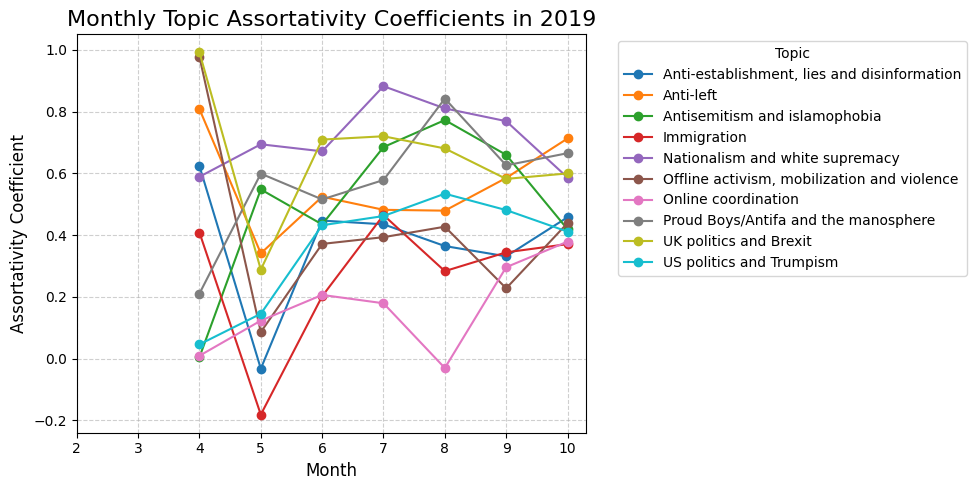

In [15]:
# Convert the monthly assortativity dictionary to a pandas DataFrame
# We need to restructure the data for plotting
assortativity_list = []
for month, topic_data in monthly_topic_assortativity_2019.items():
    if topic_data is not None:
        for topic, coeff in topic_data.items():
            if coeff is not None:
                assortativity_list.append({'month': month, 'topic': topic, 'assortativity': coeff})

assortativity_df_2019 = pd.DataFrame(assortativity_list)

# Pivot the DataFrame to have topics as columns and months as index
assortativity_pivot = assortativity_df_2019.pivot(index='month', columns='topic', values='assortativity')

# Plot the time series of topic assortativity
plt.figure(figsize=(10, 5))
for topic in assortativity_pivot.columns:
    plt.plot(assortativity_pivot.index, assortativity_pivot[topic], marker='o', linestyle='-', label=topic)

plt.title('Monthly Topic Assortativity Coefficients in 2019', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Assortativity Coefficient', fontsize=12)
plt.xticks(assortativity_pivot.index) # Ensure all months with data are shown on x-axis
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Topic', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

In [16]:
# Dictionary to store assortativity coefficients for each topic per 3-month window
window_topic_assortativity_2019 = {}

# Dictionaries to save the combined window graphs and prevalences for later use (bootstrapping, plotting...)
window_graphs_2019 = {}
window_topic_prevalence_2019 = {}

# --- Defensive checks & topic detection ---
if not isinstance(monthly_graphs_2019, dict) or len(monthly_graphs_2019) == 0:
    raise ValueError("monthly_graphs_2019 must be a non-empty dict of graphs keyed by month.")

if not isinstance(monthly_topic_prevalence_2019, dict) or len(monthly_topic_prevalence_2019) == 0:
    raise ValueError("monthly_topic_prevalence_2019 must be a non-empty dict of DataFrames keyed by month.")

# Try to infer proper chronological ordering of month keys
months_2019_keys = list(monthly_graphs_2019.keys())

def try_sort_month_keys(keys):
    try:
        # Attempt to parse keys as datetimes (works for '2019-01', '2019-01-01', etc.)
        dt_index = pd.to_datetime(keys, errors='coerce')
        if dt_index.isna().any():
            # fallback to lexical sort if any failed
            return sorted(keys)
        else:
            # return keys sorted by parsed datetime
            sorted_idx = np.argsort(dt_index.values)
            return [keys[i] for i in sorted_idx]
    except Exception:
        return sorted(keys)

months_2019 = try_sort_month_keys(months_2019_keys)

# Determine topics: prefer an explicit `topic_prevalence` variable if present, otherwise use first non-empty monthly prevalence
if 'topic_prevalence' in globals() and hasattr(topic_prevalence, "columns"):
    topics = list(topic_prevalence.columns.drop('username'))
else:
    # find first non-empty DataFrame in monthly_topic_prevalence_2019
    topics = None
    for m, df in monthly_topic_prevalence_2019.items():
        if isinstance(df, pd.DataFrame) and not df.empty:
            topics = list(df.columns.drop('username'))
            break
    if topics is None:
        raise ValueError("Could not detect topics. Ensure `topic_prevalence` or monthly_topic_prevalence_2019 contains DataFrames with columns.")

# Generate 3-month sliding windows
window_size = 3
if len(months_2019) < window_size:
    raise ValueError(f"Need at least {window_size} months to form sliding windows. Found {len(months_2019)}.")

windows = [months_2019[i:i + window_size] for i in range(len(months_2019) - window_size + 1)]

for window_months in windows:
    window_label = f"{window_months[0]}_{window_months[-1]}"
    print(f"\nCalculating assortativity for window {window_label} (2019)")

    # Combine graphs from these months (only include non-None graphs)
    valid_graphs = [monthly_graphs_2019[m] for m in window_months if monthly_graphs_2019.get(m) is not None]
    if not valid_graphs:
        print(f"No valid graphs for {window_label}. Skipping.")
        window_topic_assortativity_2019[window_label] = None
        continue

    # Merge all graphs into one
    try:
        G_window = nx.compose_all(valid_graphs)
    except Exception as e:
        print(f"Error composing graphs for {window_label}: {e}")
        window_topic_assortativity_2019[window_label] = None
        continue

    if G_window.number_of_nodes() <= 1:
        print(f"Skipping window {window_label} due to insufficient graph data (nodes <= 1).")
        window_topic_assortativity_2019[window_label] = None
        continue

    # Combine topic prevalence data across the 3 months (only include months present in the monthly_topic_prevalence_2019 dict)
    valid_prevalence = [monthly_topic_prevalence_2019[m] for m in window_months if monthly_topic_prevalence_2019.get(m) is not None]
    if not valid_prevalence:
        print(f"No topic prevalence data for {window_label}. Skipping.")
        window_topic_assortativity_2019[window_label] = None
        continue

    # Average topic prevalence over the 3 months (align by node index)
    try:
        # concat then group by index (node) and mean
        topic_prevalence_window = pd.concat(valid_prevalence).groupby(level=0).mean()
    except Exception as e:
        print(f"Could not aggregate topic prevalence for {window_label}: {e}")
        window_topic_assortativity_2019[window_label] = None
        continue

    # Save the combined window graph & prevalence for later use (bootstrapping, plotting)
    window_graphs_2019[window_label] = G_window
    window_topic_prevalence_2019[window_label] = topic_prevalence_window

    # Convert prevalence to dict-of-dicts: {node: {topic: value, ...}, ...}
    channel_topic_dict_window = topic_prevalence_window.T.to_dict()

    # Compute assortativity per topic for this window
    topic_assortativity_window = {}
    for topic in topics:
        # map only nodes that are present in the graph
        topic_attribute_map_window = {
            node: data.get(topic, 0.0)
            for node, data in channel_topic_dict_window.items()
            if node in G_window.nodes()
        }

        # proceed only if there is at least one node with non-zero prevalence for this topic
        if any(value > 0 for value in topic_attribute_map_window.values()):
            G_temp_window = G_window.copy()
            # Ensure all graph nodes exist (some nodes from prevalence may not be in G_window; we've filtered above)
            for node, value in topic_attribute_map_window.items():
                # add node if missing (safety) and set attribute
                if node not in G_temp_window:
                    G_temp_window.add_node(node)
                G_temp_window.nodes[node][topic] = value

            try:
                coeff = nx.numeric_assortativity_coefficient(G_temp_window, topic)
                # numeric_assortativity_coefficient can return nan, keep as-is
                topic_assortativity_window[topic] = coeff
            except Exception as e:
                print(f"Could not compute assortativity for topic '{topic}' in window {window_label}: {e}")
                topic_assortativity_window[topic] = None
        else:
            # No nodes with prevalence > 0 for this topic in this window
            topic_assortativity_window[topic] = None

    window_topic_assortativity_2019[window_label] = topic_assortativity_window

# Print the assortativity coefficients for each window in a safe way (handle None and NaN)
print("\n3-Month Sliding Window Topic Assortativity Coefficients (2019):")
for window_label, assortativity_data in window_topic_assortativity_2019.items():
    print(f"\nWindow {window_label}:")
    if assortativity_data:
        for topic, coeff in assortativity_data.items():
            if coeff is None or (isinstance(coeff, float) and np.isnan(coeff)):
                print(f"  {topic}: N/A")
            else:
                print(f"  {topic}: {coeff:.4f}")
    else:
        print("  No data or graph with sufficient nodes.")



Calculating assortativity for window 1_3 (2019)

Calculating assortativity for window 2_4 (2019)

Calculating assortativity for window 3_5 (2019)

Calculating assortativity for window 4_6 (2019)

Calculating assortativity for window 5_7 (2019)

Calculating assortativity for window 6_8 (2019)

Calculating assortativity for window 7_9 (2019)

Calculating assortativity for window 8_10 (2019)

3-Month Sliding Window Topic Assortativity Coefficients (2019):

Window 1_3:
  Anti-establishment, lies and disinformation: 1.0000
  Anti-left: -1.0000
  Antisemitism and islamophobia: -1.0000
  Immigration: -1.0000
  Nationalism and white supremacy: -1.0000
  Offline activism, mobilization and violence: -1.0000
  Online coordination: -1.0000
  Proud Boys/Antifa and the manosphere: -1.0000
  UK politics and Brexit: -1.0000
  US politics and Trumpism: -1.0000

Window 2_4:
  Anti-establishment, lies and disinformation: 0.6580
  Anti-left: 0.7759
  Antisemitism and islamophobia: -0.0087
  Immigration: 

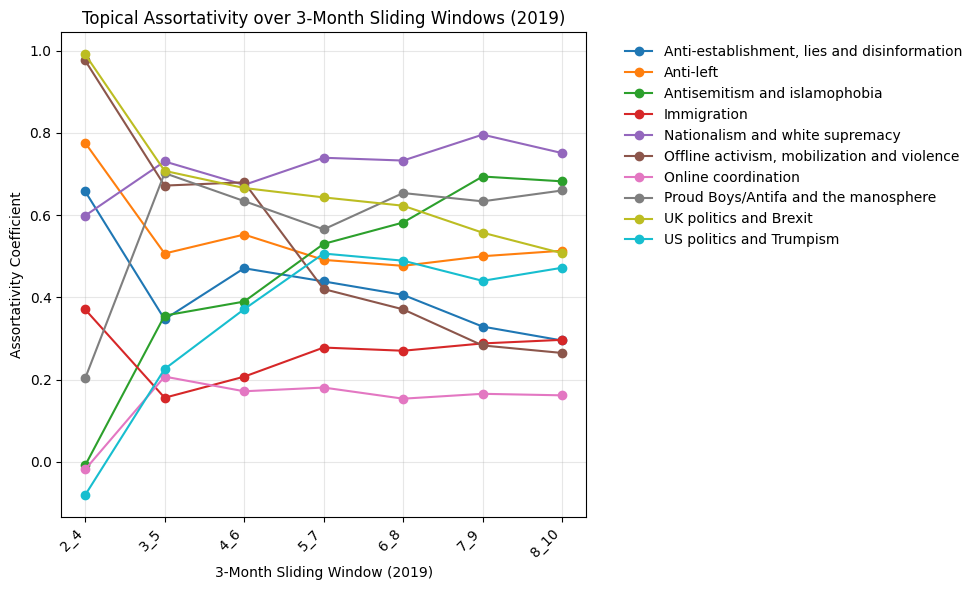

In [17]:
# Convert the nested dictionary into a DataFrame
assortativity_df = pd.DataFrame(window_topic_assortativity_2019).T

# Reset index for plotting
assortativity_df.index.name = 'window'
assortativity_df.reset_index(inplace=True)

# Optionally sort windows chronologically if the labels are month strings
# (Assumes window labels like 'Jan_Mar', 'Feb_Apr', etc.)
assortativity_df = assortativity_df.sort_values('window')

# Skip windows (e.g., insufficient data)
assortativity_df = assortativity_df.iloc[1:]

# Plotting
plt.figure(figsize=(10, 6))
for topic in assortativity_df.columns[1:]:  # Skip 'window' column
    plt.plot(
        assortativity_df['window'],
        assortativity_df[topic],
        marker='o',
        label=topic
    )

plt.xticks(rotation=45, ha='right')
plt.xlabel('3-Month Sliding Window (2019)')
plt.ylabel('Assortativity Coefficient')
plt.title('Topical Assortativity over 3-Month Sliding Windows (2019)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Bootstrapping for confidence intervals

In [18]:
# Step 1: Compute bootstrap CIs for each window and topic

from tqdm import tqdm  # for progress bar

n_bootstrap = 500  # number of resamples
ci_level = 95

bootstrap_results = {}

for window_label, G_window in tqdm(window_topic_assortativity_2019.items(), desc="Bootstrapping"):
    # If assortativity wasn't computed or graph missing, skip
    if G_window is None or window_label not in window_topic_assortativity_2019:
        continue

    # Retrieve the actual graph used for this window
    # (You should have stored these in a dict earlier as e.g. window_graphs_2019)
    G = window_graphs_2019.get(window_label)
    if G is None or G.number_of_edges() < 2:
        continue

    # Topic prevalence dictionary (same as before)
    topic_prevalence_window = window_topic_prevalence_2019.get(window_label)
    if topic_prevalence_window is None:
        continue

    channel_topic_dict = topic_prevalence_window.T.to_dict()
    topics = topic_prevalence_window.columns

    topic_bootstrap_stats = {}

    for topic in topics:
        topic_attr = {node: data.get(topic, 0.0)
                      for node, data in channel_topic_dict.items()
                      if node in G.nodes()}

        if not any(v > 0 for v in topic_attr.values()):
            topic_bootstrap_stats[topic] = {'mean': np.nan, 'ci_lower': np.nan, 'ci_upper': np.nan}
            continue

        coeff_samples = []

        for _ in range(n_bootstrap):
            # Resample edges with replacement
            edges = list(G.edges())
            sampled_edges = np.random.choice(len(edges), size=len(edges), replace=True)
            G_resampled = nx.Graph()
            G_resampled.add_edges_from([edges[i] for i in sampled_edges])

            # Add node attributes
            for node, value in topic_attr.items():
                G_resampled.add_node(node, **{topic: value})

            try:
                coeff = nx.numeric_assortativity_coefficient(G_resampled, topic)
                coeff_samples.append(coeff)
            except Exception:
                coeff_samples.append(np.nan)

        # Compute statistics
        coeff_samples = np.array(coeff_samples)
        mean_val = np.nanmean(coeff_samples)
        lower = np.nanpercentile(coeff_samples, (100 - ci_level) / 2)
        upper = np.nanpercentile(coeff_samples, 100 - (100 - ci_level) / 2)

        topic_bootstrap_stats[topic] = {
            'mean': mean_val,
            'ci_lower': lower,
            'ci_upper': upper
        }

    bootstrap_results[window_label] = topic_bootstrap_stats

Bootstrapping:   0%|          | 0/8 [00:00<?, ?it/s]

Bootstrapping: 100%|██████████| 8/8 [00:15<00:00,  1.92s/it]


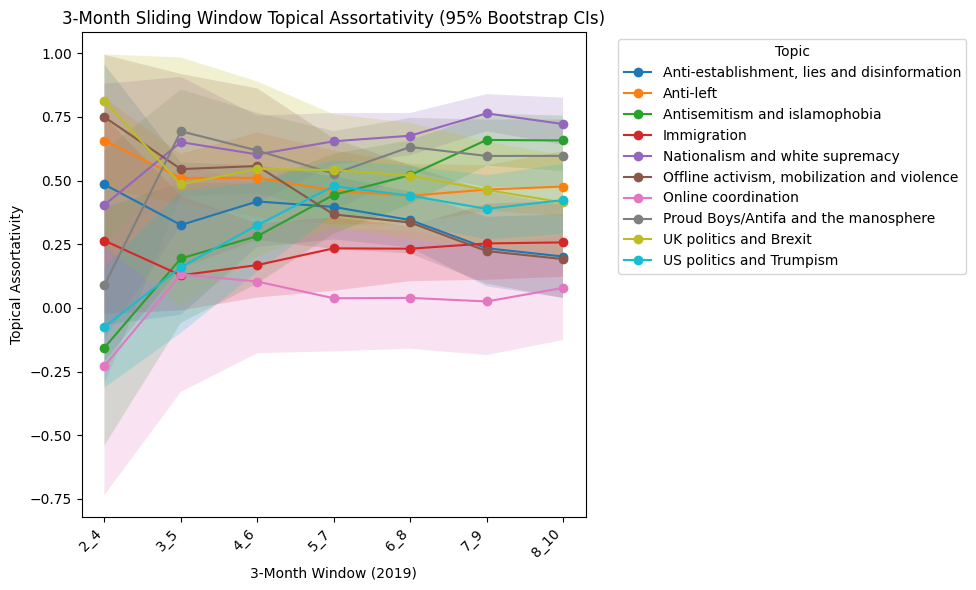

In [19]:
# Convert bootstrap results to a DataFrame
records = []
for window_label, topic_data in bootstrap_results.items():
    for topic, stats in topic_data.items():
        records.append({
            'window': window_label,
            'topic': topic,
            'mean': stats['mean'],
            'ci_lower': stats['ci_lower'],
            'ci_upper': stats['ci_upper']
        })

df_boot = pd.DataFrame(records).dropna(subset=['mean'])

# Sort window labels chronologically (e.g., 'Jan_Mar', 'Feb_Apr', etc.)
sorted_windows = sorted(df_boot['window'].unique(), key=str)

# Skip the first window (insufficient data)
if len(sorted_windows) > 1:
    sorted_windows = sorted_windows[1:]

df_boot = df_boot[df_boot['window'].isin(sorted_windows)]
df_boot['window'] = pd.Categorical(df_boot['window'], categories=sorted_windows, ordered=True)

# Plot with confidence intervals
fig, ax = plt.subplots(figsize=(10, 6))

for topic in df_boot['topic'].unique():
    df_t = df_boot[df_boot['topic'] == topic]
    ax.plot(df_t['window'], df_t['mean'], marker='o', label=topic)
    ax.fill_between(df_t['window'], df_t['ci_lower'], df_t['ci_upper'], alpha=0.2)

ax.set_xlabel("3-Month Window (2019)")
ax.set_ylabel("Topical Assortativity")
ax.set_title("3-Month Sliding Window Topical Assortativity (95% Bootstrap CIs)")
ax.legend(title="Topic", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


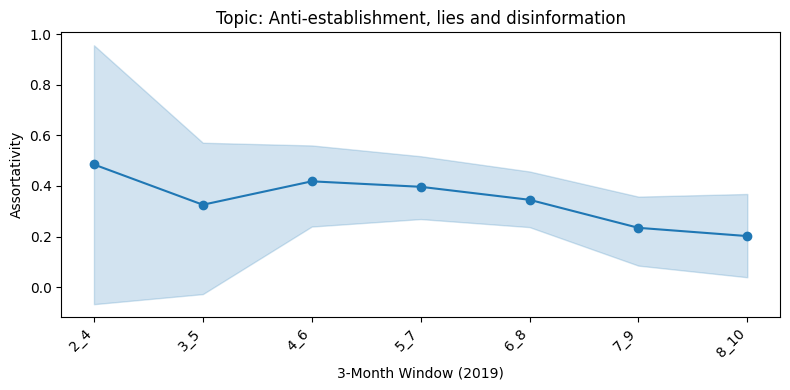

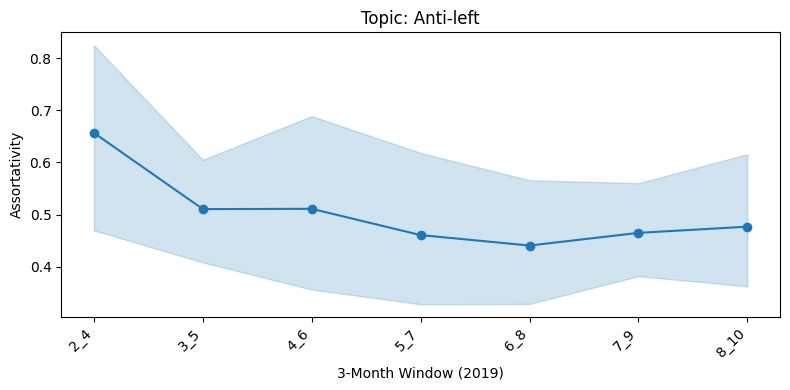

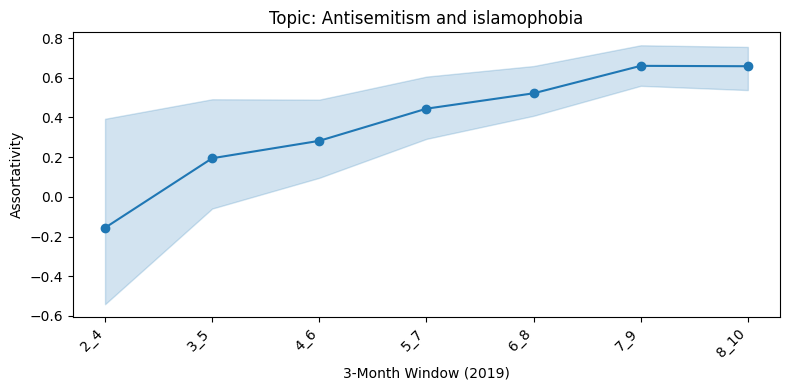

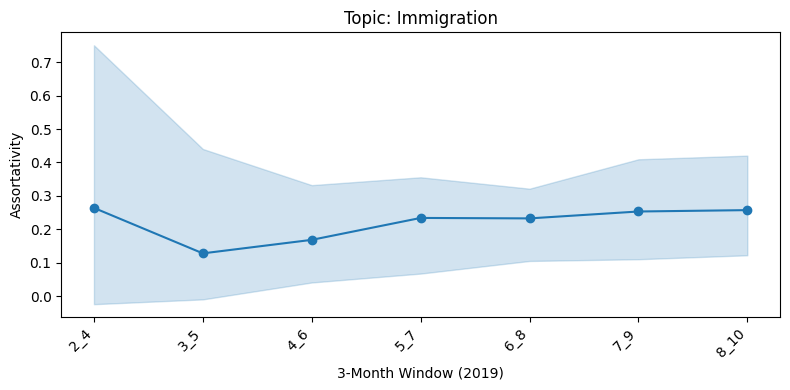

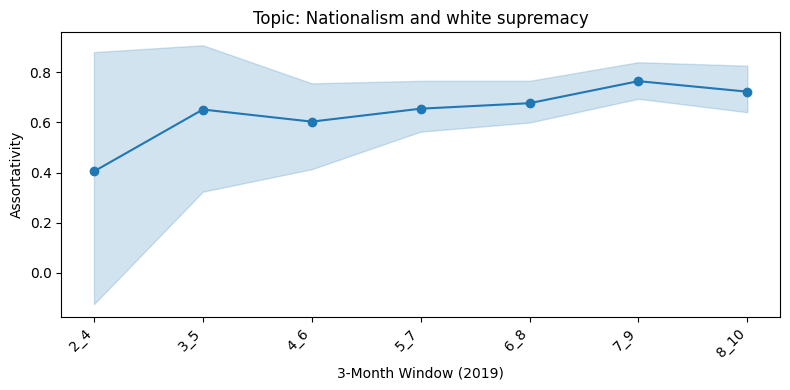

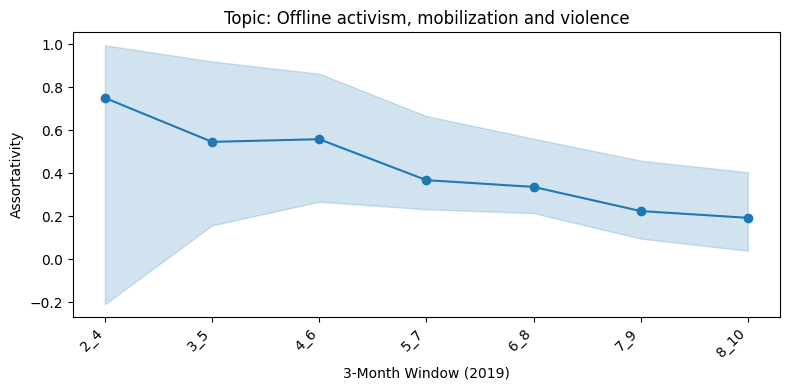

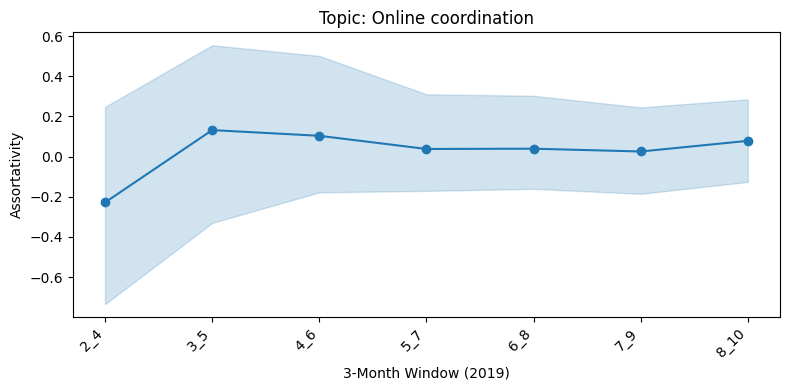

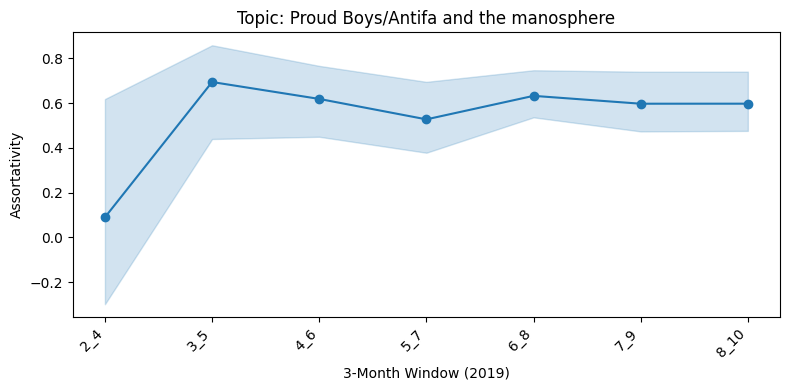

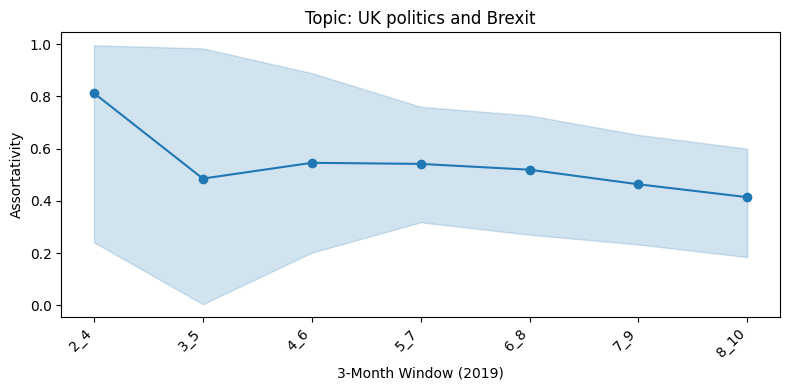

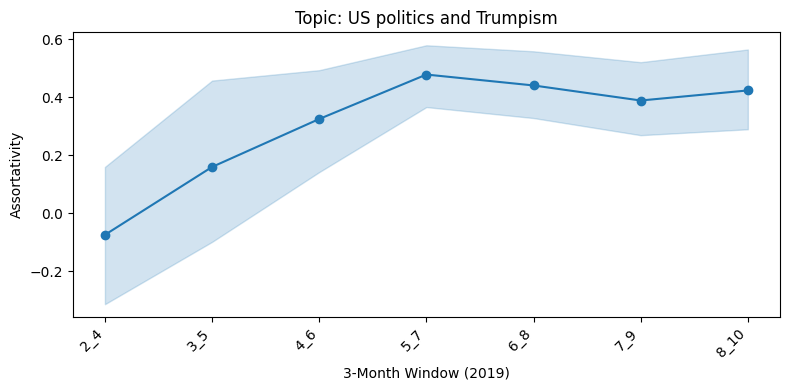

In [20]:
# Convert bootstrap results to DataFrame (same as before)
records = []
for window_label, topic_data in bootstrap_results.items():
    for topic, stats in topic_data.items():
        records.append({
            'window': window_label,
            'topic': topic,
            'mean': stats['mean'],
            'ci_lower': stats['ci_lower'],
            'ci_upper': stats['ci_upper']
        })

df_boot = pd.DataFrame(records).dropna(subset=['mean'])

# Sort window labels chronologically
sorted_windows = sorted(df_boot['window'].unique(), key=str)

# Skip first window (if needed)
if len(sorted_windows) > 1:
    sorted_windows = sorted_windows[1:]

df_boot = df_boot[df_boot['window'].isin(sorted_windows)]
df_boot['window'] = pd.Categorical(df_boot['window'], categories=sorted_windows, ordered=True)

# --- Separate plots per topic ---
for topic in df_boot['topic'].unique():
    df_t = df_boot[df_boot['topic'] == topic]
    plt.figure(figsize=(8, 4))
    plt.plot(df_t['window'], df_t['mean'], marker='o', color='C0')
    plt.fill_between(df_t['window'], df_t['ci_lower'], df_t['ci_upper'], alpha=0.2, color='C0')
    plt.title(f"Topic: {topic}")
    plt.xlabel("3-Month Window (2019)")
    plt.ylabel("Assortativity")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


*NB*: During the preparation of the manuscript, I unfortunately did not set a seed value to ensure exact reproducibility of neither the permutation test nor the bootstrap results. Nonetheless, results are stable across random runs.